# Will This Visitor Buy? — E-commerce Purchase Intention Prediction

**Goal:** Predict whether an online shopping session ends with a purchase (`Revenue`).

**Dataset:** UCI Online Shoppers Purchasing Intention Dataset (12,330 sessions, 17 input features).

This notebook follows the project workflow: problem framing, data understanding, EDA, preprocessing, baseline, three ML algorithms, cross-validation, tuning, test evaluation, business insights, and saving a pipeline for Streamlit.

## 1. Problem framing

An e-commerce business wants to identify browsing sessions that are likely to result in a purchase. The prediction can help the business decide when to show assistance or recommendations.

- **Unit:** one browsing session.
- **Target:** `Revenue` (`True` = purchase, `False` = no purchase).
- **Task:** binary classification.
- **Business metric:** F1 and recall for the purchase class, supported by ROC-AUC. Accuracy alone can be misleading because the classes are imbalanced.
- **Important limitation:** predictions support decisions; they should not be treated as certainty.

In [1]:
# 2. Imports and reproducibility
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42
Path("models").mkdir(exist_ok=True)
Path("reports").mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 3. Load the dataset

The dataset is fetched from the UCI repository using dataset ID `468`. An internet connection is required for the first download.

In [2]:
dataset = fetch_ucirepo(id=468)
X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# UCI target is Boolean-like; convert it to 0/1.
target_col = y.columns[0]
y = y[target_col].astype(str).str.lower().map({"true": 1, "false": 0})

df = X.copy()
df["Revenue"] = y
print("Dataset shape:", df.shape)
display(df.head())
print("\\nTarget counts:")
display(df["Revenue"].value_counts().rename(index={0: "No purchase", 1: "Purchase"}))

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


\nTarget counts:


Revenue
No purchase    10422
Purchase        1908
Name: count, dtype: int64

## 4. Data understanding

Check data types, missing values, duplicates, and class balance before modeling.

In [3]:
display(df.info())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

None

Missing values: 0
Duplicate rows: 125


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


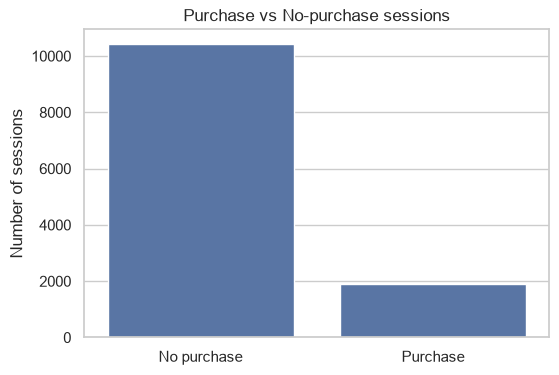

Purchase rate: 15.47 %


In [4]:
# Target distribution
target_counts = df["Revenue"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
sns.barplot(x=["No purchase", "Purchase"], y=target_counts.values)
plt.title("Purchase vs No-purchase sessions")
plt.ylabel("Number of sessions")
plt.show()

print("Purchase rate:", round(df["Revenue"].mean() * 100, 2), "%")

## 5. Exploratory Data Analysis (EDA)

We inspect numerical distributions and relationships with the target. The charts are exploratory; they do not prove causation.

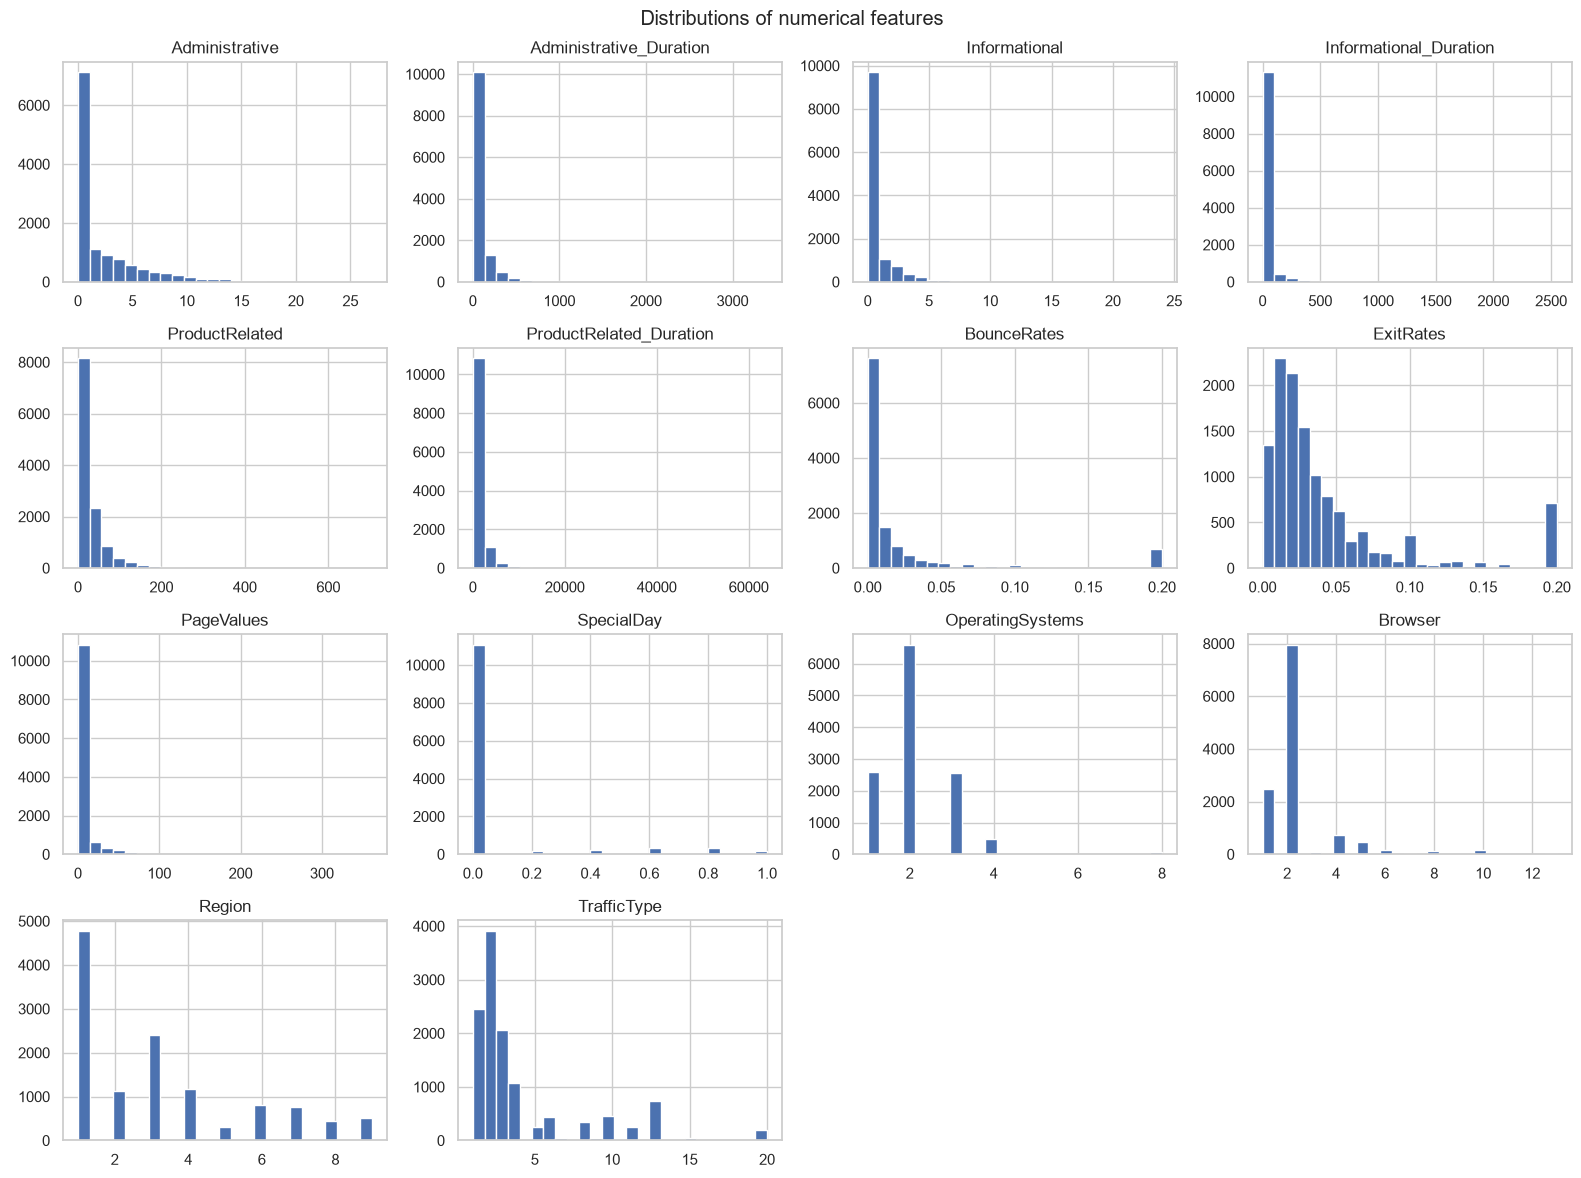

In [5]:
numeric_cols_all = df.select_dtypes(include=np.number).columns.drop("Revenue").tolist()
df[numeric_cols_all].hist(figsize=(16, 12), bins=25)
plt.suptitle("Distributions of numerical features")
plt.tight_layout()
plt.show()

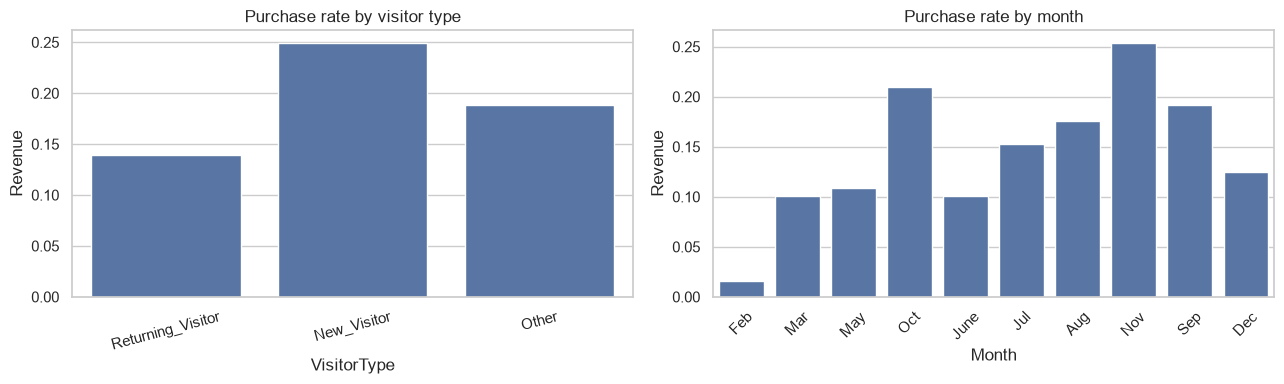

In [6]:
# Purchase rate by visitor type and month
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df, x="VisitorType", y="Revenue", estimator=np.mean, errorbar=None, ax=axes[0])
axes[0].set_title("Purchase rate by visitor type")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=df, x="Month", y="Revenue", estimator=np.mean, errorbar=None, ax=axes[1])
axes[1].set_title("Purchase rate by month")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

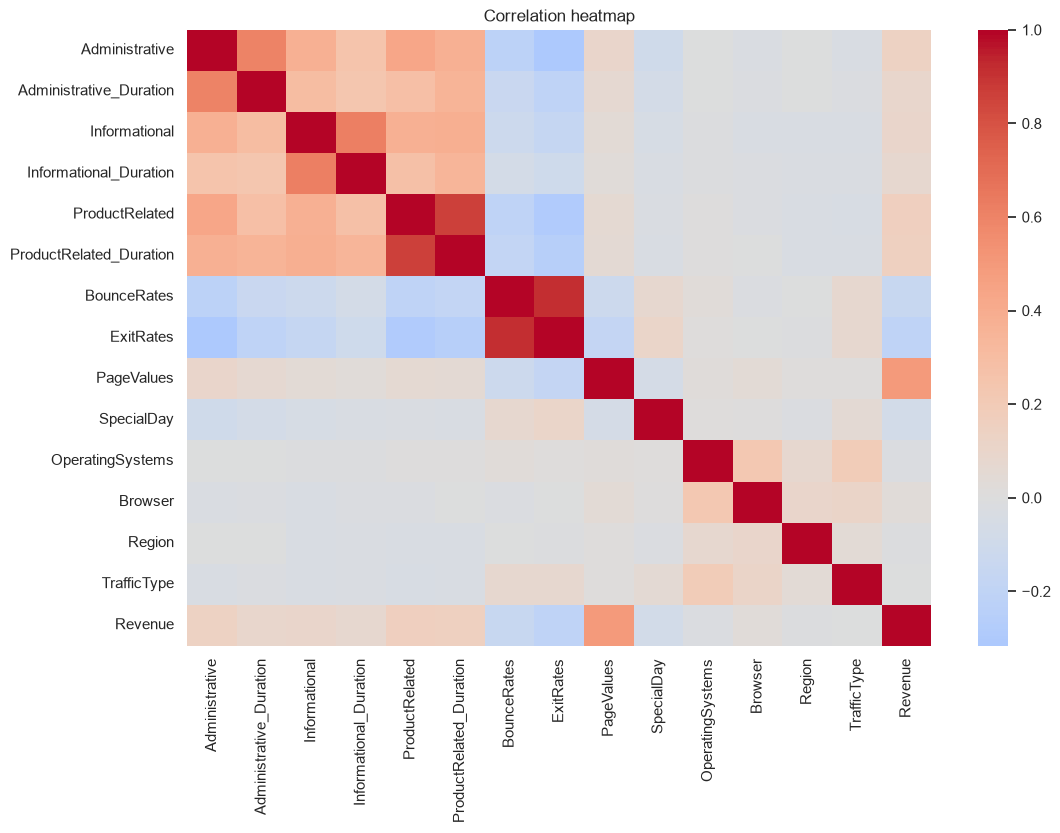

In [7]:
# Correlation heatmap for numerical variables
plt.figure(figsize=(12, 8))
sns.heatmap(df[numeric_cols_all + ["Revenue"]].corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

### EDA insights — complete after running the charts

Write 3–5 observations based on the actual outputs. For example, describe which visitor group has a higher observed purchase rate, which numeric features are skewed, and whether the target is imbalanced. Do not copy assumed values; read them from your charts and output.

## 6. Preprocessing and train/test split

Split the data **before fitting preprocessing steps** to avoid data leakage. Numerical columns are imputed and scaled. Categorical columns are imputed and one-hot encoded. The preprocessing is kept inside each scikit-learn pipeline.

In [8]:
X = df.drop(columns="Revenue")
y = df["Revenue"].astype(int)

# Treat ID-like coded fields as categorical rather than continuous measurements.
categorical_cols = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend"]
numeric_cols = [col for col in X.columns if col not in categorical_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training purchase rate:", round(y_train.mean(), 3))
print("Test purchase rate:", round(y_test.mean(), 3))

Train shape: (9864, 17)
Test shape: (2466, 17)
Training purchase rate: 0.155
Test purchase rate: 0.155


## 7. Baseline and three classification algorithms

We compare:
1. Dummy Classifier (most frequent class) — baseline.
2. Logistic Regression.
3. Decision Tree.
4. Random Forest.

Stratified cross-validation preserves the approximate class ratio in each fold.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=250, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
}

cv_rows = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring={"accuracy": "accuracy", "precision": "precision",
                 "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"},
        n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC", ascending=False)
display(cv_results.round(3))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
3,Random Forest,0.895,0.644,0.722,0.681,0.928
1,Logistic Regression,0.853,0.517,0.765,0.617,0.904
2,Decision Tree,0.864,0.559,0.577,0.567,0.747
0,Baseline (most frequent),0.845,0.000,0.000,0.000,0.500


## 8. Hyperparameter tuning

Tune Random Forest using GridSearchCV on the training set only. The held-out test set remains untouched until final evaluation.

In [10]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))
])

param_grid = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 12],
    "model__min_samples_leaf": [1, 3]
}

grid_search = GridSearchCV(
    rf_pipeline, param_grid=param_grid, scoring="roc_auc",
    cv=cv, n_jobs=-1, verbose=1
)
grid_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(grid_search.best_score_, 4))
print("Best parameters:", grid_search.best_params_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV ROC-AUC: 0.9288
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 150}


## 9. Final evaluation on the untouched test set

The tuned Random Forest is evaluated once on the test set. Review precision and recall for the positive (`Purchase`) class, not accuracy alone.

In [11]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
display(pd.DataFrame([test_metrics]).round(4))
print(classification_report(y_test, y_pred, target_names=["No purchase", "Purchase"], zero_division=0))

,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.8686,0.5543,0.7749,0.6463,0.9213


              precision    recall  f1-score   support

 No purchase       0.96      0.89      0.92      2084
    Purchase       0.55      0.77      0.65       382

    accuracy                           0.87      2466
   macro avg       0.75      0.83      0.78      2466
weighted avg       0.89      0.87      0.88      2466



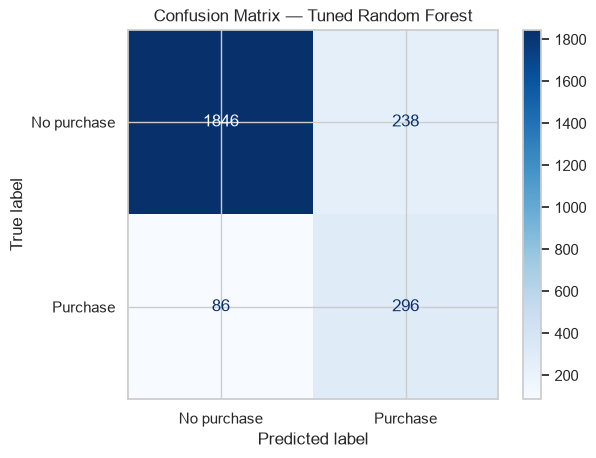

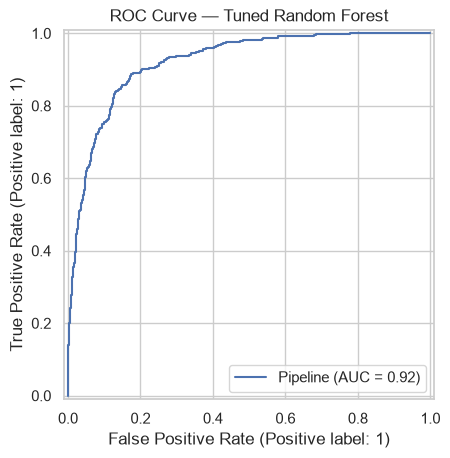

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No purchase", "Purchase"], cmap="Blues"
)
plt.title("Confusion Matrix — Tuned Random Forest")
plt.show()

RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("ROC Curve — Tuned Random Forest")
plt.show()

## 10. Business insights, limitations, and recommendation

After running the notebook, replace the prompts below with your measured results.

- **Best model:** report the tuned model and its measured test metrics.
- **Business meaning:** explain how the model could help prioritize assistance or recommendations for sessions with higher purchase probability.
- **Class imbalance:** only a minority of sessions end in a purchase, so accuracy by itself is insufficient.
- **Limitations:** the data represents sessions from one dataset/time period; behavior and conversion patterns may change. Predictions are probabilistic and should be monitored.
- **Responsible use:** use the model as decision support, not as the sole basis for denying offers or treating customers differently.

## 11. Save the complete pipeline for the Streamlit app

The saved object includes preprocessing and the trained classifier. The app passes a one-row DataFrame with the same feature names.

In [13]:
model_path = Path("models/purchase_intention_pipeline.joblib")
joblib.dump(best_model, model_path)

metrics_path = Path("reports/test_metrics.csv")
pd.DataFrame([test_metrics]).to_csv(metrics_path, index=False)

print("Saved model to:", model_path)
print("Saved metrics to:", metrics_path)

Saved model to: models\purchase_intention_pipeline.joblib
Saved metrics to: reports\test_metrics.csv


## 12. Conclusion

This project demonstrates a complete classical machine-learning workflow for binary classification: data understanding, EDA, leakage-safe preprocessing, baseline comparison, three algorithms, cross-validation, hyperparameter tuning, test evaluation, and deployment preparation.

**Dataset citation:** Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q (CC BY 4.0).